# Multi-Regional Marketing Mix Model with Google Meridian
### Conjura eCommerce dataset — full Bayesian MMM workflow

This notebook builds a **geo-level (multi-regional) MMM** with [Google Meridian](https://developers.google.com/meridian) on the Conjura MMM timeseries schema, covering:

1. **Data loading & preprocessing** — daily → weekly, territory geos, 9 paid media channels, organic/owned controls
2. **Model specification** — custom ROI priors, geo hierarchy, adstock + Hill saturation
3. **Prior sampling** and full **MCMC posterior sampling** (NUTS) — all chains & samples inspected
4. **MCMC diagnostics** — trace plots with the **burn-in / warm-up region drawn and shaded**, R-hat, ESS
5. **Prior vs. posterior** distribution comparison per channel
6. **Control variable** effects
7. **Results** — model fit, ROI, contribution decomposition, response curves, adstock decay
8. **Budget optimization** and an exportable HTML summary report

> ⚠️ **Runtime note:** Meridian runs on TensorFlow Probability. A GPU (e.g. Colab T4) makes posterior sampling ~10–50× faster. On CPU, reduce `N_KEEP`/`N_ADAPT` in the config cell.


## 0. Environment setup

In [ ]:

import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import arviz as az
import tensorflow as tf
import tensorflow_probability as tfp

from meridian import constants
from meridian.data import load
from meridian.model import model, spec, prior_distribution
from meridian.analysis import analyzer, visualizer, optimizer, summarizer, formatter

import IPython

print('TensorFlow :', tf.__version__)
print('TFP        :', tfp.__version__)
print('ArviZ      :', az.__version__)
print('GPU devices:', tf.config.list_physical_devices('GPU') or 'none (CPU mode — reduce sampling sizes)')

RNG = np.random.default_rng(42)
plt.rcParams['figure.dpi'] = 110


TensorFlow : 2.20.0
TFP        : 0.26.0-dev20260130
ArviZ      : 0.19.0
GPU devices: none (CPU mode — reduce sampling sizes)


## 1. Configuration

All the knobs in one place. `DATA_PATH` should point to your Conjura extract (CSV or parquet) with the columns from the data dictionary. If the file is not found, the notebook **simulates a realistic dataset with the exact same schema** so the whole pipeline runs end-to-end.

In [138]:
# ------------------------- DATA -------------------------
DATA_PATH = 'data/conjura_mmm_data.csv'      # <-- point this at your extract

# Which organisation to model. None = auto-pick the org with the most
# country-level territory splits (best candidate for a multi-regional model).
ORGANISATION_ID = None

# ------------------------- MODEL ------------------------
KPI_TYPE = 'revenue'          # model net revenue directly
WEEKLY_FREQ = 'W-MON'         # aggregate daily data to weeks starting Monday

# Media channels: (spend column, impressions column, clicks column, pretty name)
MEDIA_CHANNELS = [
    ('GOOGLE_PAID_SEARCH_SPEND', 'GOOGLE_PAID_SEARCH_IMPRESSIONS', 'GOOGLE_PAID_SEARCH_CLICKS', 'Google Paid Search'),
    ('GOOGLE_SHOPPING_SPEND',    'GOOGLE_SHOPPING_IMPRESSIONS',    'GOOGLE_SHOPPING_CLICKS',    'Google Shopping'),
    ('GOOGLE_PMAX_SPEND',        'GOOGLE_PMAX_IMPRESSIONS',        'GOOGLE_PMAX_CLICKS',        'Google PMax'),
    ('GOOGLE_DISPLAY_SPEND',     'GOOGLE_DISPLAY_IMPRESSIONS',     'GOOGLE_DISPLAY_CLICKS',     'Google Display'),
    ('GOOGLE_VIDEO_SPEND',       'GOOGLE_VIDEO_IMPRESSIONS',       'GOOGLE_VIDEO_CLICKS',       'Google Video'),
    ('META_FACEBOOK_SPEND',      'META_FACEBOOK_IMPRESSIONS',      'META_FACEBOOK_CLICKS',      'Meta Facebook'),
    ('META_INSTAGRAM_SPEND',     'META_INSTAGRAM_IMPRESSIONS',     'META_INSTAGRAM_CLICKS',     'Meta Instagram'),
    ('META_OTHER_SPEND',         'META_OTHER_IMPRESSIONS',         'META_OTHER_CLICKS',         'Meta Other'),
    ('TIKTOK_SPEND',             'TIKTOK_IMPRESSIONS',             'TIKTOK_CLICKS',             'TikTok'),
]

# Control variables: organic / owned traffic that co-moves with demand.
# NB: per the data dictionary, *_GROSS_DISCOUNT is only observed for completed
# purchases -> using it as a control leaks the outcome. We exclude it.
CONTROL_COLS = [
    'BRANDED_SEARCH_CLICKS',   # brand demand proxy
    'ORGANIC_SEARCH_CLICKS',
    'EMAIL_CLICKS',
    'REFERRAL_CLICKS',
    'DIRECT_CLICKS',
    'ALL_OTHER_CLICKS',
]

# ------------------------- MCMC -------------------------
N_CHAINS      = 4      # number of Markov chains
N_ADAPT       = 1000   # NUTS adaptation steps (always discarded by Meridian)
N_BURNIN_VIS  = 500    # burn-in draws we KEEP so we can *draw* them, then discard
N_KEEP        = 1000   # post-burn-in draws per chain used for inference
N_PRIOR_DRAWS = 500    # draws from the prior for prior-vs-posterior plots
SEED          = 42

FAST_MODE = False     # True = tiny sampling for a quick CPU smoke test (~3 min)
if FAST_MODE:
    N_CHAINS, N_ADAPT, N_BURNIN_VIS, N_KEEP, N_PRIOR_DRAWS = 2, 100, 50, 80, 100

print(f'Total MCMC draws per chain : {N_ADAPT} adapt + {N_BURNIN_VIS} burn-in + {N_KEEP} keep')
print(f'Total posterior samples    : {N_CHAINS} chains x {N_KEEP} = {N_CHAINS * N_KEEP}')


Total MCMC draws per chain : 1000 adapt + 500 burn-in + 1000 keep
Total posterior samples    : 4 chains x 1000 = 4000


## 2. Load the data

Reads your extract if present; otherwise simulates ~2 years of daily data for one organisation across 5 country territories with the **identical schema**, including known ground-truth ROIs (handy for validating the pipeline).

In [139]:
import os

SCHEMA_COLS = (
    ['MMM_TIMESERIES_ID', 'ORGANISATION_ID', 'ORGANISATION_VERTICAL', 'ORGANISATION_SUBVERTICAL',
     'ORGANISATION_MARKETING_SOURCES', 'ORGANISATION_PRIMARY_TERRITORY_NAME', 'TERRITORY_NAME',
     'DATE_DAY', 'CURRENCY_CODE',
     'FIRST_PURCHASES', 'FIRST_PURCHASES_UNITS', 'FIRST_PURCHASES_ORIGINAL_PRICE', 'FIRST_PURCHASES_GROSS_DISCOUNT',
     'ALL_PURCHASES', 'ALL_PURCHASES_UNITS', 'ALL_PURCHASES_ORIGINAL_PRICE', 'ALL_PURCHASES_GROSS_DISCOUNT']
    + [c for ch in MEDIA_CHANNELS for c in ch[:3]]
    + CONTROL_COLS
)


def simulate_conjura_data(n_days=730, seed=42):
    """Simulate daily multi-territory data matching the Conjura schema."""
    rng = np.random.default_rng(seed)
    territories = ['US', 'GB', 'DE', 'FR', 'AU', 'JP']
    base_scale  = {'US': 1.0, 'GB': 0.55, 'DE': 0.4, 'FR': 0.3, 'AU': 0.2, 'JP': 0.15}
    ccy         = {'US': 'USD', 'GB': 'GBP', 'DE': 'EUR', 'FR': 'EUR', 'AU': 'AUD', 'JP': 'JPY'}
    start_lag   = {'US': 0, 'GB': 0, 'DE': 0, 'FR': 30, 'AU': 0, 'JP': 400}  # JP launches late

    # ground-truth ROI per channel (revenue per unit spend) — for validation
    true_roi = {'Google Paid Search': 3.5, 'Google Shopping': 2.8, 'Google PMax': 3.0,
                'Google Display': 0.8, 'Google Video': 1.2, 'Meta Facebook': 2.2,
                'Meta Instagram': 2.6, 'Meta Other': 1.0, 'TikTok': 1.6}

    rows = []
    for ts_id, geo in enumerate(territories, start=1):
        s = base_scale[geo]
        lag = start_lag[geo]
        dates = pd.date_range('2022-07-01', periods=n_days, freq='D')[lag:]
        t = np.arange(lag, n_days)
        nd = len(t)
        season = 1 + 0.25 * np.sin(2 * np.pi * (t - 330) / 365.25)         # annual seasonality, Q4 peak
        weekday = 1 + 0.10 * np.sin(2 * np.pi * t / 7)
        trend = 1 + 0.0004 * t
        demand = season * weekday * trend

        spends, media_rev = {}, np.zeros(nd)
        for spend_c, imp_c, clk_c, name in MEDIA_CHANNELS:
            base_spend = s * rng.uniform(80, 400)
            raw = base_spend * demand * np.exp(rng.normal(0, 0.35, nd))
            raw *= rng.binomial(1, 0.97, nd)                            # occasional dark days
            # simple geometric adstock + diminishing returns for the true effect
            ad = np.zeros(nd); carry = rng.uniform(0.2, 0.6)
            for i in range(nd):
                ad[i] = raw[i] + (carry * ad[i - 1] if i else 0)
            sat = ad / (1 + ad / (3 * base_spend))
            media_rev += true_roi[name] * sat * (raw.sum() / max(sat.sum(), 1e-9)) * 0.9
            spends[spend_c] = raw
            spends[imp_c] = raw * rng.uniform(180, 260) * np.exp(rng.normal(0, 0.10, nd))
            spends[clk_c] = raw * rng.uniform(1.2, 2.4) * np.exp(rng.normal(0, 0.12, nd))

        organic = s * 800 * demand * np.exp(rng.normal(0, 0.2, nd))
        baseline_rev = s * 2500 * demand * np.exp(rng.normal(0, 0.15, nd)) + 1.8 * organic
        revenue_gross = baseline_rev + media_rev
        discount = revenue_gross * rng.uniform(0.10, 0.20)
        aov = 95 * np.exp(rng.normal(0, 0.05, nd))
        purchases = np.maximum(1, np.round((revenue_gross - discount) / aov)).astype(int)

        df_g = pd.DataFrame({
            'MMM_TIMESERIES_ID': ts_id,
            'ORGANISATION_ID': 'demo_org_beauty_haircare',
            'ORGANISATION_VERTICAL': 'Beauty & Fitness',
            'ORGANISATION_SUBVERTICAL': 'Hair Care',
            'ORGANISATION_MARKETING_SOURCES': 'Google, Meta, Tiktok',
            'ORGANISATION_PRIMARY_TERRITORY_NAME': 'US',
            'TERRITORY_NAME': geo,
            'DATE_DAY': dates,
            'CURRENCY_CODE': ccy[geo],
            'ALL_PURCHASES': purchases,
            'ALL_PURCHASES_UNITS': (purchases * rng.uniform(1.1, 1.4)).astype(int),
            'ALL_PURCHASES_ORIGINAL_PRICE': revenue_gross,
            'ALL_PURCHASES_GROSS_DISCOUNT': discount,
            'FIRST_PURCHASES': (purchases * rng.uniform(0.45, 0.65, nd)).astype(int),
            'FIRST_PURCHASES_UNITS': (purchases * rng.uniform(0.5, 0.8, nd)).astype(int),
            'FIRST_PURCHASES_ORIGINAL_PRICE': revenue_gross * rng.uniform(0.4, 0.6, nd),
            'FIRST_PURCHASES_GROSS_DISCOUNT': discount * rng.uniform(0.4, 0.6, nd),
            'BRANDED_SEARCH_CLICKS': 0.4 * organic * np.exp(rng.normal(0, 0.25, nd)),
            'ORGANIC_SEARCH_CLICKS': organic,
            'EMAIL_CLICKS': 0.15 * organic * np.exp(rng.normal(0, 0.3, nd)),
            'REFERRAL_CLICKS': 0.05 * organic * np.exp(rng.normal(0, 0.4, nd)),
            'DIRECT_CLICKS': 0.5 * organic * np.exp(rng.normal(0, 0.2, nd)),
            'ALL_OTHER_CLICKS': 0.08 * organic * np.exp(rng.normal(0, 0.5, nd)),
        })
        for c, v in spends.items():
            df_g[c] = v
        rows.append(df_g)

    out = pd.concat(rows, ignore_index=True)
    print('Simulated dataset with ground-truth ROIs:', true_roi)
    return out


if os.path.exists(DATA_PATH):
    raw_df = (pd.read_parquet(DATA_PATH) if DATA_PATH.endswith('.parquet')
              else pd.read_csv(DATA_PATH))
    raw_df.columns = [c.upper() for c in raw_df.columns]
    print(f'Loaded {DATA_PATH}: {raw_df.shape[0]:,} rows')
else:
    print(f'"{DATA_PATH}" not found -> simulating demo data with the same schema.')
    raw_df = simulate_conjura_data()

raw_df['DATE_DAY'] = pd.to_datetime(raw_df['DATE_DAY'])
missing = [c for c in SCHEMA_COLS if c not in raw_df.columns]
for c in missing:
    raw_df[c] = np.nan
print('Rows:', len(raw_df), '| Territories:', raw_df['TERRITORY_NAME'].nunique(),
      '| Orgs:', raw_df['ORGANISATION_ID'].nunique())
raw_df.head(3)


Loaded data/conjura_mmm_data.csv: 132,759 rows
Rows: 132759 | Territories: 19 | Orgs: 93


,MMM_TIMESERIES_ID,ORGANISATION_ID,ORGANISATION_VERTICAL,ORGANISATION_SUBVERTICAL,ORGANISATION_MARKETING_SOURCES,ORGANISATION_PRIMARY_TERRITORY_NAME,TERRITORY_NAME,DATE_DAY,CURRENCY_CODE,FIRST_PURCHASES,...,META_FACEBOOK_IMPRESSIONS,META_INSTAGRAM_IMPRESSIONS,META_OTHER_IMPRESSIONS,TIKTOK_IMPRESSIONS,DIRECT_CLICKS,BRANDED_SEARCH_CLICKS,ORGANIC_SEARCH_CLICKS,EMAIL_CLICKS,REFERRAL_CLICKS,ALL_OTHER_CLICKS
0,596eef7c71f933d820d0e485935d0e8f,04769dac8b828ec7a85676d9e2bffe6f,Beauty & Fitness,Hair Care,"Google, Meta",US,All Territories,2022-07-29,USD,22,...,18997.0,NaN,NaN,NaN,139.0,NaN,300.0,1.0,61.0,40.0
1,596eef7c71f933d820d0e485935d0e8f,04769dac8b828ec7a85676d9e2bffe6f,Beauty & Fitness,Hair Care,"Google, Meta",US,All Territories,2022-07-30,USD,14,...,20188.0,NaN,NaN,NaN,209.0,NaN,442.0,8.0,110.0,62.0
2,596eef7c71f933d820d0e485935d0e8f,04769dac8b828ec7a85676d9e2bffe6f,Beauty & Fitness,Hair Care,"Google, Meta",US,All Territories,2022-07-31,USD,31,...,24718.0,NaN,NaN,NaN,262.0,NaN,427.0,631.0,108.0,65.0


## 3. Select organisation & geos for the multi-regional model

Meridian's hierarchical geo model needs **one KPI per geo per period with shared media channels**. We model a single organisation and use its **country-level territory splits as geos**, dropping the `All Territories` roll-up to avoid double counting. Mixed currencies across territories are flagged — convert to a common currency upstream if needed.

In [140]:
df = raw_df.copy()

if ORGANISATION_ID is None:
    # pick the org with the most country-level territories
    counts = (df[df['TERRITORY_NAME'] != 'All Territories']
              .groupby('ORGANISATION_ID')['TERRITORY_NAME'].nunique()
              .sort_values(ascending=False))
    if len(counts) and counts.iloc[0] >= 2:
        ORGANISATION_ID = counts.index[0]
    else:  # no territory splits anywhere -> fall back to orgs-as-geos
        ORGANISATION_ID = None
        print('No org has >=2 country territories; using organisations as geos instead.')

if ORGANISATION_ID is not None:
    df = df[df['ORGANISATION_ID'] == ORGANISATION_ID].copy()
    geos_available = sorted(df.loc[df['TERRITORY_NAME'] != 'All Territories', 'TERRITORY_NAME'].unique())
    if len(geos_available) >= 2:
        df = df[df['TERRITORY_NAME'].isin(geos_available)]
        df['geo'] = df['TERRITORY_NAME']
    else:
        df['geo'] = df['TERRITORY_NAME']  # single 'All Territories' geo -> national model
    print(f'Modelling organisation {ORGANISATION_ID}')
else:
    df = df[df['TERRITORY_NAME'] == 'All Territories'].copy()
    df['geo'] = df['ORGANISATION_ID'].str[:8]

currencies = df.groupby('geo')['CURRENCY_CODE'].agg(lambda s: s.dropna().unique())
print('Currency by geo:')
print(currencies)
print('\nGeos:', sorted(df['geo'].unique()))
print('Date range:', df['DATE_DAY'].min().date(), '→', df['DATE_DAY'].max().date())


Modelling organisation ba773ebd7ec0a08f1d042187d086ccb4
Currency by geo:
geo
Australia    [AUD]
Austria      [EUR]
Canada       [CAD]
France       [EUR]
Germany      [EUR]
Hong Kong    [HKD]
Ireland      [EUR]
Italy        [EUR]
Japan        [JPY]
Spain        [EUR]
UK           [GBP]
US           [USD]
Name: CURRENCY_CODE, dtype: object

Geos: ['Australia', 'Austria', 'Canada', 'France', 'Germany', 'Hong Kong', 'Ireland', 'Italy', 'Japan', 'Spain', 'UK', 'US']
Date range: 2020-01-06 → 2024-06-02


### 3b. Convert everything to one currency

Revenue and spend must be in a **single currency** before pooling geos — otherwise the hierarchical priors and cross-geo ROI comparisons are meaningless. We convert all monetary columns to `TARGET_CURRENCY` using the rate table below.

> The static rates here are placeholders — replace them with your finance team's averages, or merge a **dated FX series** on `DATE_DAY` for better accuracy (rates drifted meaningfully over 2022-2026).

In [141]:
TARGET_CURRENCY = 'USD'

# units of TARGET_CURRENCY per 1 unit of local currency  <-- REPLACE with your rates
FX_TO_TARGET = {
    'USD': 1.00,
    'EUR': 1.09,
    'GBP': 1.27,
    'AUD': 0.66,
    'CAD': 0.74,
    'HKD': 0.128,
    'JPY': 0.0067,
}

monetary_cols = [c for c in df.columns if c.endswith('_SPEND')] + [
    'ALL_PURCHASES_ORIGINAL_PRICE', 'ALL_PURCHASES_GROSS_DISCOUNT',
    'FIRST_PURCHASES_ORIGINAL_PRICE', 'FIRST_PURCHASES_GROSS_DISCOUNT']

unknown = set(df['CURRENCY_CODE'].dropna().unique()) - set(FX_TO_TARGET)
assert not unknown, f'Add FX rates for: {unknown}'

fx = df['CURRENCY_CODE'].map(FX_TO_TARGET).fillna(1.0)
for c in monetary_cols:
    df[c] = pd.to_numeric(df[c], errors='coerce').fillna(0.0) * fx
df['CURRENCY_CODE'] = TARGET_CURRENCY
print(f'Converted {len(monetary_cols)} monetary columns to {TARGET_CURRENCY}.')


Converted 13 monetary columns to USD.


## 4. Preprocess: daily → weekly geo panel

Meridian is designed for weekly data. We aggregate, define:
- **KPI** = net revenue = `ALL_PURCHASES_ORIGINAL_PRICE − ALL_PURCHASES_GROSS_DISCOUNT`
- **Media execution** = channel **impressions** (falls back to clicks, then spend, per channel if impressions are missing)
- **Controls** = organic/owned click channels, centred & scaled per geo
- **Population proxy** per geo (used by Meridian for hierarchical scaling) = mean weekly purchases

In [142]:
spend_cols = [c[0] for c in MEDIA_CHANNELS]
imp_cols   = [c[1] for c in MEDIA_CHANNELS]
clk_cols   = [c[2] for c in MEDIA_CHANNELS]
num_cols   = spend_cols + imp_cols + clk_cols + CONTROL_COLS + [
    'ALL_PURCHASES', 'ALL_PURCHASES_ORIGINAL_PRICE', 'ALL_PURCHASES_GROSS_DISCOUNT']
for c in num_cols:
    df[c] = pd.to_numeric(df[c], errors='coerce').fillna(0.0)

wk = (df.set_index('DATE_DAY')
        .groupby('geo')[num_cols]
        .resample(WEEKLY_FREQ).sum()
        .reset_index()
        .rename(columns={'DATE_DAY': 'time'}))

# drop partial first/last weeks (fewer than 7 days of data)
day_counts = (df.set_index('DATE_DAY').groupby('geo')['ALL_PURCHASES']
                .resample(WEEKLY_FREQ).size().rename('n_days').reset_index()
                .rename(columns={'DATE_DAY': 'time'}))
wk = wk.merge(day_counts, on=['geo', 'time'])
full_weeks = wk.groupby('time')['n_days'].min() == 7
wk = wk[wk['time'].isin(full_weeks[full_weeks].index)].drop(columns='n_days')

wk['revenue'] = wk['ALL_PURCHASES_ORIGINAL_PRICE'] - wk['ALL_PURCHASES_GROSS_DISCOUNT']

# keep only channels with meaningful spend in this org (>0.5% of total spend)
tot = wk[spend_cols].sum()
active = tot[tot > 0.005 * tot.sum()].index.tolist()
ACTIVE_CHANNELS = [ch for ch in MEDIA_CHANNELS if ch[0] in active]
print(f'Active media channels ({len(ACTIVE_CHANNELS)}/{len(MEDIA_CHANNELS)}):',
      [ch[3] for ch in ACTIVE_CHANNELS])

# media execution: impressions -> clicks -> spend fallback
media_cols, media_map, spend_map = [], {}, {}
for spend_c, imp_c, clk_c, name in ACTIVE_CHANNELS:
    exec_c = imp_c if wk[imp_c].sum() > 0 else (clk_c if wk[clk_c].sum() > 0 else spend_c)
    media_cols.append(exec_c)
    media_map[exec_c] = name
    spend_map[spend_c] = name

# population proxy per geo
pop = (wk.groupby('geo')['ALL_PURCHASES'].mean().rename('population') * 52).round()
wk = wk.merge(pop, on='geo')



Active media channels (4/9): ['Google Paid Search', 'Google Shopping', 'Google PMax', 'Meta Facebook']


### 4b-bis. Holiday controls

Holidays are the textbook confounder: marketing budgets are planned *around* them (heavier spend into Black Friday and Christmas) **and** they independently move sales — so omitting them lets media steal holiday credit. Three features per geo-week:

- `HOLIDAY_COUNT` — number of national public holidays in the week, **per territory** (Japan's Golden Week ≠ US Thanksgiving ≠ German public holidays). Because it varies *across* geos, it adds identification the shared time-varying intercept cannot: the knots absorb calendar effects common to all geos, but not geo-specific ones.
- `BFCM_WEEK` — Black Friday / Cyber Monday week (global eCommerce event).
- `XMAS_PEAK_WEEK` — the Dec 18–24 gifting peak.

The two global dummies partially overlap with a flexible knot spline — with dense knots they may add little (and the collinearity pruning below will say so); with sparse knots they capture one-week spikes the spline smooths over. The geo-varying holiday count is useful either way.

In [143]:
import holidays as pyholidays
from datetime import date, timedelta

GEO_TO_COUNTRY = {
    'US': 'US', 'UK': 'GB', 'GB': 'GB', 'Germany': 'DE', 'DE': 'DE',
    'France': 'FR', 'FR': 'FR', 'Italy': 'IT', 'IT': 'IT', 'Spain': 'ES',
    'ES': 'ES', 'Ireland': 'IE', 'IE': 'IE', 'Austria': 'AT', 'AT': 'AT',
    'Australia': 'AU', 'AU': 'AU', 'Canada': 'CA', 'CA': 'CA',
    'Japan': 'JP', 'JP': 'JP', 'Hong Kong': 'HK', 'HK': 'HK',
}

years = list(range(int(wk['time'].dt.year.min()), int(wk['time'].dt.year.max()) + 2))

hol_sets = {}
for g in wk['geo'].unique():
    code_ = GEO_TO_COUNTRY.get(g)
    if code_ is None:
        print(f'⚠️  No holiday-calendar mapping for geo "{g}" — its HOLIDAY_COUNT will be 0. '
              'Add it to GEO_TO_COUNTRY.')
        hol_sets[g] = set()
    else:
        hol_sets[g] = set(pyholidays.country_holidays(code_, years=years).keys())

def black_friday(y):
    thursdays = [date(y, 11, d) for d in range(1, 31) if date(y, 11, d).weekday() == 3]
    return thursdays[3] + timedelta(days=1)          # day after 4th Thursday

bfcm_days, xmas_days = set(), set()
for y in years:
    bf = black_friday(y)
    bfcm_days |= {bf + timedelta(days=k) for k in range(4)}      # Fri → Cyber Monday
    xmas_days |= {date(y, 12, d) for d in range(18, 25)}         # Dec 18–24

def week_days(ts):
    # weekly label from resample(W-MON) marks the END of the week: covers ts-6 … ts
    end = ts.date()
    return [end - timedelta(days=k) for k in range(7)]

wk['HOLIDAY_COUNT'] = [sum(d in hol_sets[g] for d in week_days(t))
                       for g, t in zip(wk['geo'], wk['time'])]
wk['BFCM_WEEK'] = [int(any(d in bfcm_days for d in week_days(t))) for t in wk['time']]
wk['XMAS_PEAK_WEEK'] = [int(any(d in xmas_days for d in week_days(t))) for t in wk['time']]

HOLIDAY_CONTROLS = ['HOLIDAY_COUNT', 'BFCM_WEEK', 'XMAS_PEAK_WEEK']
print(wk.groupby('geo')['HOLIDAY_COUNT'].sum().rename('total holiday-days in panel'))
print('\nBFCM weeks flagged:', int(wk.groupby('time')['BFCM_WEEK'].first().sum()),
      '| Xmas-peak weeks flagged:', int(wk.groupby('time')['XMAS_PEAK_WEEK'].first().sum()))


geo
Australia    29
Austria      18
Canada       22
France       46
Germany      37
Hong Kong    39
Ireland      21
Italy        53
Japan        19
Spain        34
UK           33
US           52
Name: total holiday-days in panel, dtype: int64

BFCM weeks flagged: 4 | Xmas-peak weeks flagged: 8


In [144]:
controls = ([c for c in CONTROL_COLS if wk[c].sum() > 0]
            + [c for c in HOLIDAY_CONTROLS if wk[c].sum() > 0])

# drop near-perfectly correlated controls (|r| > 0.95) — Meridian's EDA
# guardrail rejects collinear controls, and they destabilise the baseline
corr = wk[controls].corr().abs()
drop = set()
for i, a in enumerate(controls):
    for b in controls[i + 1:]:
        if b not in drop and a not in drop and corr.loc[a, b] > 0.95:
            drop.add(b)
            print(f'Dropping control {b} (|r|={corr.loc[a, b]:.3f} with {a})')
controls = [c for c in controls if c not in drop]
print('Controls used:', controls)

model_df = wk[['geo', 'time', 'revenue', 'population'] + media_cols
              + [c[0] for c in ACTIVE_CHANNELS] + controls].copy()
model_df['time'] = model_df['time'].dt.strftime('%Y-%m-%d')

model_df.head()


Controls used: ['BRANDED_SEARCH_CLICKS', 'ORGANIC_SEARCH_CLICKS', 'EMAIL_CLICKS', 'REFERRAL_CLICKS', 'ALL_OTHER_CLICKS', 'HOLIDAY_COUNT', 'BFCM_WEEK', 'XMAS_PEAK_WEEK']


,geo,time,revenue,population,GOOGLE_PAID_SEARCH_IMPRESSIONS,GOOGLE_SHOPPING_IMPRESSIONS,GOOGLE_PMAX_IMPRESSIONS,META_FACEBOOK_IMPRESSIONS,GOOGLE_PAID_SEARCH_SPEND,GOOGLE_SHOPPING_SPEND,GOOGLE_PMAX_SPEND,META_FACEBOOK_SPEND,BRANDED_SEARCH_CLICKS,ORGANIC_SEARCH_CLICKS,EMAIL_CLICKS,REFERRAL_CLICKS,ALL_OTHER_CLICKS,HOLIDAY_COUNT,BFCM_WEEK,XMAS_PEAK_WEEK
0,Australia,2020-09-21,106136.7318,17770.0,457.0,592040.0,0.0,235.0,17.4768,3527.5218,0.0,10.0320,0.0,291.0,42.0,146.0,22.0,0,0,0
1,Australia,2020-09-28,77880.4026,17770.0,437.0,628724.0,0.0,220.0,13.1406,4098.7386,0.0,8.5272,1.0,341.0,73.0,141.0,23.0,0,0,0
2,Australia,2020-10-05,75802.9998,17770.0,251.0,582645.0,0.0,90.0,15.4836,3547.5990,0.0,3.8940,0.0,362.0,69.0,201.0,35.0,0,0,0
3,Australia,2020-10-12,97329.7908,17770.0,492.0,598018.0,0.0,0.0,17.4042,3733.8246,0.0,0.0000,0.0,509.0,95.0,219.0,74.0,0,0,0
4,Australia,2020-10-19,88680.6030,17770.0,211.0,521057.0,0.0,0.0,6.8640,2931.2778,0.0,0.0000,0.0,212.0,37.0,114.0,16.0,0,0,0


### 4c. Balance the panel

Meridian needs a **rectangular panel**: every geo observed for the exact same set of weeks. Real territories launch at different times (e.g. a geo with 63 weeks of history vs. one with 218), so we must trade off **geo coverage vs. history length**:

- keep *all* geos → the panel is clipped to the shortest common window
- drop late-launch geos → longer history for the rest

The diagnostic below shows the trade-off for every threshold; pick via `MIN_WEEKS` (drop geos with less history than this) or force an explicit `KEEP_GEOS` list. Weeks missing in *any* kept geo are dropped for *all* geos.

In [145]:
KEEP_GEOS = None    # e.g. ['US', 'UK', 'Germany', ...]  — overrides MIN_WEEKS
MIN_WEEKS = 100     # drop geos whose history is shorter than this

weeks_by_geo = model_df.groupby('geo')['time'].agg(set)
counts = weeks_by_geo.apply(len).sort_values(ascending=False)
print('Weeks of history per geo:')
print(counts.to_string())

# trade-off table: for each candidate cut, how long is the common window?
print('\nTrade-off (drop geos below threshold -> common weeks across the rest):')
for thr in sorted(counts.unique()):
    kept = counts[counts >= thr].index
    common = set.intersection(*weeks_by_geo[kept]) if len(kept) else set()
    print(f'  keep {len(kept):>2} geos (>= {thr:>3} wks) -> {len(common):>3} common weeks')

kept_geos = (list(KEEP_GEOS) if KEEP_GEOS is not None
             else counts[counts >= MIN_WEEKS].index.tolist())
if not kept_geos:
    print(f'⚠️  No geo has >= {MIN_WEEKS} weeks — keeping all geos instead. '
          'Lower MIN_WEEKS or set KEEP_GEOS explicitly.')
    kept_geos = counts.index.tolist()
dropped_geos = [g for g in counts.index if g not in kept_geos]
common_weeks = sorted(set.intersection(*weeks_by_geo[kept_geos]))

# Meridian requires *regularly spaced* time coords -> keep the longest
# contiguous run of consecutive weeks within the common window
cw = pd.Series(pd.to_datetime(common_weeks)).sort_values().reset_index(drop=True)
run_id = (cw.diff().dt.days.fillna(7) != 7).cumsum()
best_run = run_id.value_counts().idxmax()
contiguous = cw[run_id == best_run]
if len(contiguous) < len(cw):
    print(f'⚠️  Dropped {len(cw) - len(contiguous)} common weeks outside the longest '
          f'contiguous run (Meridian needs evenly spaced weeks).')
common_weeks = set(contiguous.dt.strftime('%Y-%m-%d'))

model_df = model_df[model_df['geo'].isin(kept_geos)
                    & model_df['time'].isin(common_weeks)].copy()

# gaps inside the common window would already be excluded by the intersection,
# so the panel is now rectangular by construction — verify:
n_geos, n_weeks = model_df['geo'].nunique(), model_df['time'].nunique()
print(f'\nKept geos ({n_geos}): {kept_geos}')
if dropped_geos:
    print(f'Dropped geos ({len(dropped_geos)}): {dropped_geos}')
print(f'Balanced panel: {n_geos} geos × {n_weeks} weeks = {len(model_df)} rows '
      f'({model_df.time.min()} → {model_df.time.max()})')
assert len(model_df) == n_geos * n_weeks, 'Panel still unbalanced — inspect weeks_by_geo.'
if n_weeks < 52:
    print('⚠️  Fewer than 52 common weeks — seasonality is poorly identified. '
          'Consider dropping short-history geos (raise MIN_WEEKS).')


Weeks of history per geo:
geo
Germany      218
US           217
UK           211
France       209
Italy        208
Spain        203
Australia    187
Canada       187
Hong Kong    127
Ireland      110
Austria       64
Japan         63

Trade-off (drop geos below threshold -> common weeks across the rest):
  keep 12 geos (>=  63 wks) ->   0 common weeks
  keep 11 geos (>=  64 wks) ->  64 common weeks
  keep 10 geos (>= 110 wks) -> 110 common weeks
  keep  9 geos (>= 127 wks) -> 127 common weeks
  keep  8 geos (>= 187 wks) -> 187 common weeks
  keep  6 geos (>= 203 wks) -> 203 common weeks
  keep  5 geos (>= 208 wks) -> 208 common weeks
  keep  4 geos (>= 209 wks) -> 209 common weeks
  keep  3 geos (>= 211 wks) -> 211 common weeks
  keep  2 geos (>= 217 wks) -> 217 common weeks
  keep  1 geos (>= 218 wks) -> 218 common weeks
⚠️  Dropped 35 common weeks outside the longest contiguous run (Meridian needs evenly spaced weeks).

Kept geos (10): ['Germany', 'US', 'UK', 'France', 'Italy', 'Spai

### 4b. Quick look at the inputs

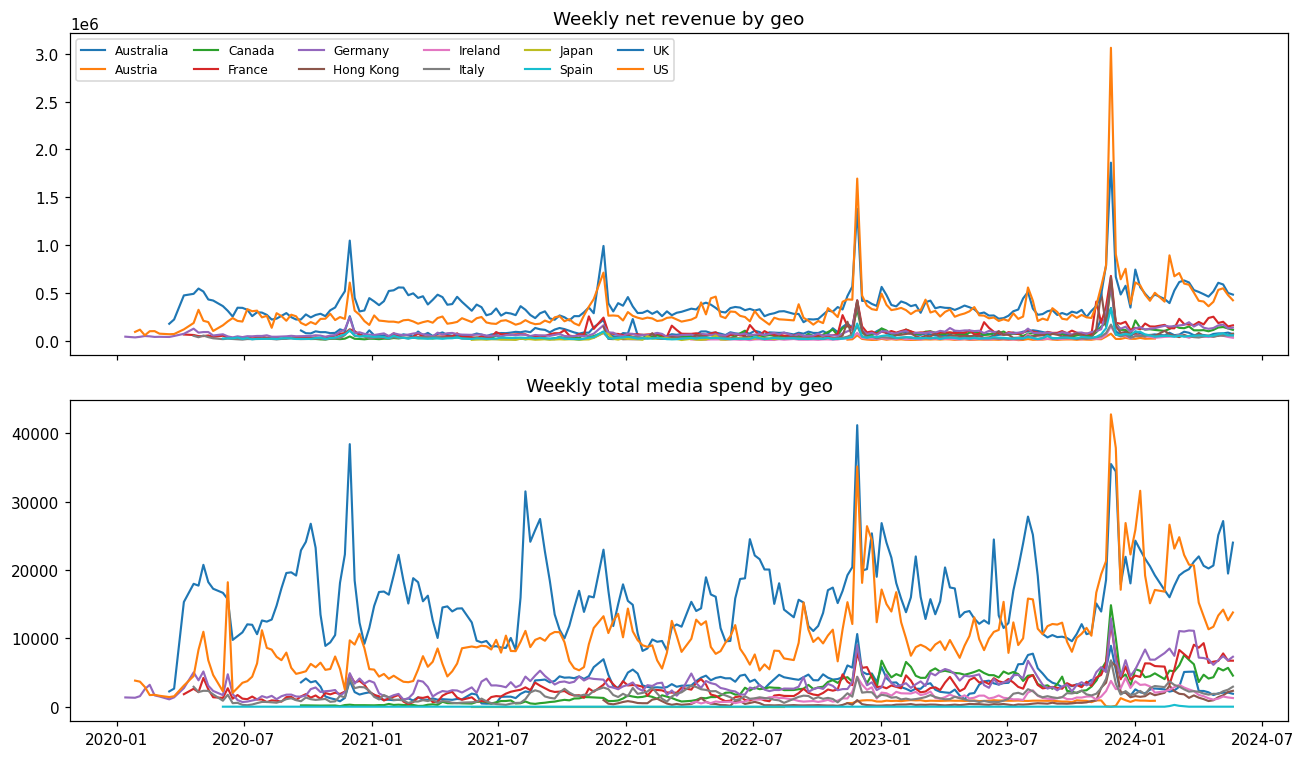

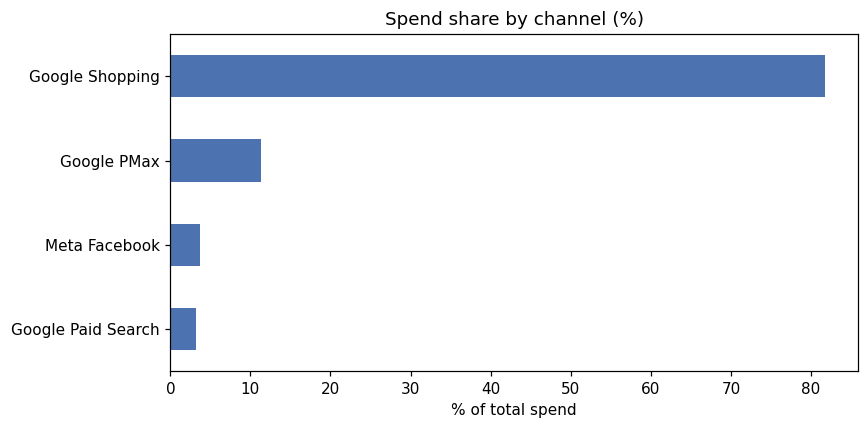

In [146]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
for g, gdf in wk.groupby('geo'):
    axes[0].plot(gdf['time'], gdf['revenue'], label=g, lw=1.4)
    axes[1].plot(gdf['time'], gdf[[c[0] for c in ACTIVE_CHANNELS]].sum(axis=1), lw=1.4)
axes[0].set_title('Weekly net revenue by geo'); axes[0].legend(ncol=6, fontsize=8)
axes[1].set_title('Weekly total media spend by geo')
for ax in axes:
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
plt.tight_layout(); plt.show()

share = wk[[c[0] for c in ACTIVE_CHANNELS]].sum()
share.index = [c[3] for c in ACTIVE_CHANNELS]
ax = (share / share.sum() * 100).sort_values().plot.barh(figsize=(8, 4), color='#4C72B0')
ax.set_title('Spend share by channel (%)'); ax.set_xlabel('% of total spend')
plt.tight_layout(); plt.show()


## 5. Build the Meridian `InputData`

`DataFrameDataLoader` maps our tidy panel to Meridian's tensors: `kpi` (revenue), `media` (impressions), `media_spend`, `controls`, `population`, indexed by `(geo, time)`.

In [147]:
coord_to_columns = load.CoordToColumns(
    time='time',
    geo='geo',
    kpi='revenue',
    population='population',
    controls=controls,
    media=media_cols,
    media_spend=[c[0] for c in ACTIVE_CHANNELS],
)

loader = load.DataFrameDataLoader(
    df=model_df,
    kpi_type=KPI_TYPE,                       # 'revenue' -> KPI is monetary
    coord_to_columns=coord_to_columns,
    media_to_channel=media_map,              # execution column  -> channel name
    media_spend_to_channel={c[0]: c[3] for c in ACTIVE_CHANNELS},
)
data = loader.load()

print('KPI tensor        :', data.kpi.shape, ' (geo × time)')
print('Media tensor      :', data.media.shape, ' (geo × media_time × channel)')
print('Media spend tensor:', data.media_spend.shape)
print('Controls tensor   :', data.controls.shape)
print('Channels          :', list(data.media_channel.values))
print('Geos              :', list(data.geo.values))


KPI tensor        : (10, 75)  (geo × time)
Media tensor      : (10, 75, 4)  (geo × media_time × channel)
Media spend tensor: (10, 75, 4)
Controls tensor   : (10, 75, 8)
Channels          : ['Google Paid Search', 'Google Shopping', 'Google PMax', 'Meta Facebook']
Geos              : [np.str_('Australia'), np.str_('Canada'), np.str_('France'), np.str_('Germany'), np.str_('Hong Kong'), np.str_('Ireland'), np.str_('Italy'), np.str_('Spain'), np.str_('UK'), np.str_('US')]


## 6. Model specification & priors

We put a **log-normal prior on each channel's ROI** — the recommended Meridian calibration lever. Here we use a weakly-informative shared prior (median ROI ≈ 1.6, wide); with lift tests or benchmarks you can set channel-specific `mu`/`sigma`. Geo-level media effects are partially pooled via the hierarchical `eta_m` parameters; `knots` controls the flexibility of the baseline time effect.

In [148]:
roi_mu    = 0.5   # log-space mean  -> median ROI = exp(0.5) ≈ 1.65
roi_sigma = 0.7   # wide: 95% prior mass roughly ROI ∈ [0.4, 6.5]

prior = prior_distribution.PriorDistribution(
    roi_m=tfp.distributions.LogNormal(roi_mu, roi_sigma, name=constants.ROI_M),
)

model_spec = spec.ModelSpec(
    prior=prior,
    max_lag=8,                        # up to 8 weeks of adstock carryover
    knots=max(1, int(0.3 * n_weeks)), # baseline flexibility (~1 knot / 3-4 weeks)
    paid_media_prior_type='roi',
    hill_before_adstock=False,
    media_effects_dist='log_normal',
)

mmm = model.Meridian(input_data=data, model_spec=model_spec)
print(mmm)
print('\nROI prior: LogNormal(mu={}, sigma={})'.format(roi_mu, roi_sigma))



ROI prior: LogNormal(mu=0.5, sigma=0.7)


## 7. Sample from the prior

In [149]:
%%time
mmm.sample_prior(N_PRIOR_DRAWS, seed=SEED)
print('Prior groups:', list(mmm.inference_data.groups()))
print('Prior roi_m shape (chain, draw, channel):', mmm.inference_data.prior['roi_m'].shape)


Prior groups: ['prior']
Prior roi_m shape (chain, draw, channel): (1, 500, 4)
CPU times: user 436 ms, sys: 121 ms, total: 557 ms
Wall time: 789 ms


## 8. Posterior sampling — the Markov chains

Meridian runs **NUTS (No-U-Turn HMC)** via TensorFlow Probability. Normally `n_burnin` draws are discarded internally — which would make it impossible to *see* the burn-in. Trick: we set `n_burnin=0` and instead **keep** the first `N_BURNIN_VIS` post-adaptation draws, plot them shaded as the burn-in/warm-up region, and then discard them manually before any inference.

Per chain: `N_ADAPT` adaptation steps (step-size/mass-matrix tuning, always discarded) → `N_BURNIN_VIS` visualised burn-in draws → `N_KEEP` inference draws.

In [150]:
%%time
mmm.sample_posterior(
    n_chains=N_CHAINS,
    n_adapt=N_ADAPT,
    n_burnin=0,                      # keep 'burn-in' draws so we can draw them
    n_keep=N_BURNIN_VIS + N_KEEP,    # burn-in + inference draws
    seed=SEED,
)

post = mmm.inference_data.posterior
n_c, n_d = post.sizes['chain'], post.sizes['draw']
print(f'\nChains: {n_c} | Draws kept per chain: {n_d} '
      f'(first {N_BURNIN_VIS} = burn-in, last {N_KEEP} = inference)')
print(f'Total draws across chains: {n_c * n_d}')
print('\nSampled parameter blocks:')
for name, v in post.data_vars.items():
    print(f'  {name:<22} {tuple(v.shape)}')


2026-08-02 18:04:52.314329: W tensorflow/compiler/tf2xla/kernels/assert_op.cc:39] Ignoring Assert operator mcmc_retry_init/assert_equal_1/Assert/AssertGuard/Assert



Chains: 4 | Draws kept per chain: 1500 (first 500 = burn-in, last 1000 = inference)
Total draws across chains: 6000

Sampled parameter blocks:
  alpha_m                (4, 1500, 4)
  beta_gm                (4, 1500, 10, 4)
  beta_m                 (4, 1500, 4)
  ec_m                   (4, 1500, 4)
  eta_m                  (4, 1500, 4)
  gamma_c                (4, 1500, 8)
  gamma_gc               (4, 1500, 10, 8)
  knot_values            (4, 1500, 22)
  mu_t                   (4, 1500, 75)
  roi_m                  (4, 1500, 4)
  sigma                  (4, 1500)
  slope_m                (4, 1500, 4)
  tau_g                  (4, 1500, 10)
  xi_c                   (4, 1500, 8)
CPU times: user 3min 40s, sys: 5.95 s, total: 3min 46s
Wall time: 3min 39s


## 9. Trace plots with the burn-in / warm-up region drawn

Every Markov chain for every channel's ROI, full history. The shaded orange band is the burn-in we discard; the grey band marks the (already-discarded) adaptation phase conceptually preceding draw 0.

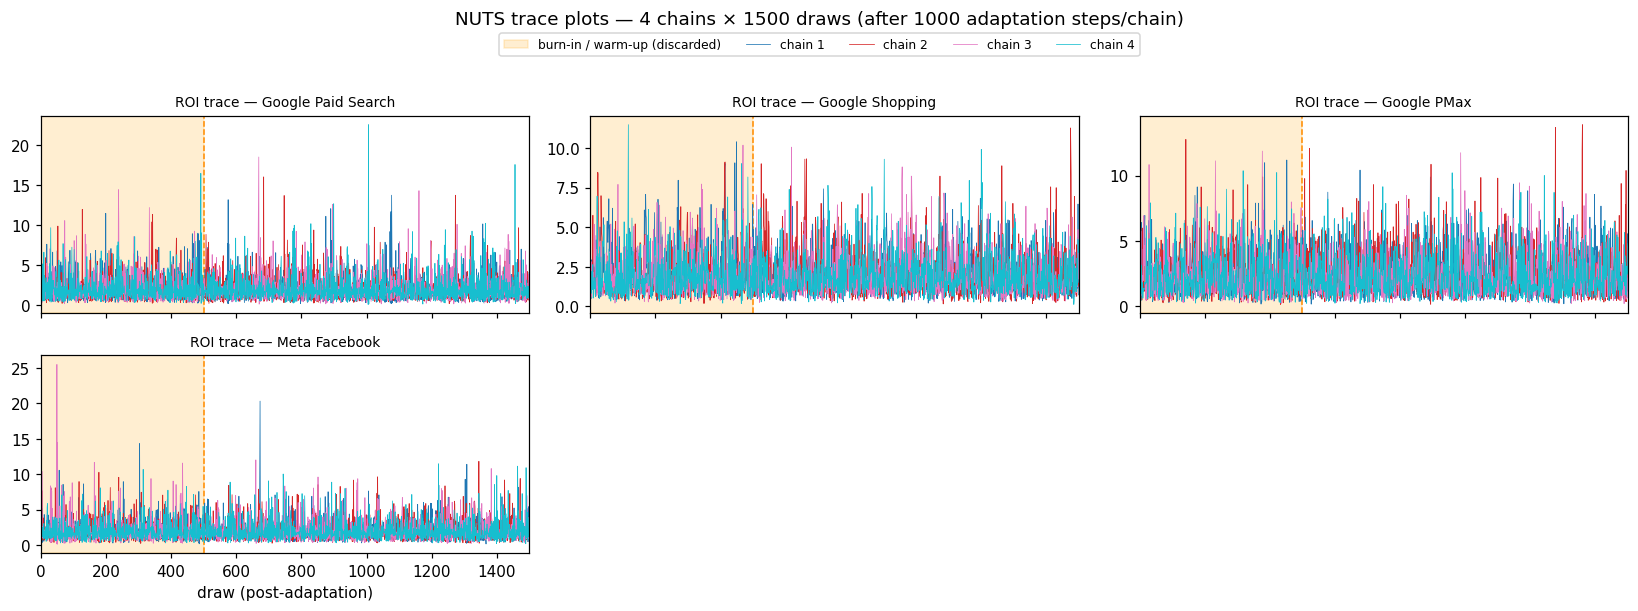

In [151]:
channels = list(post['media_channel'].values)
chain_colors = plt.cm.tab10(np.linspace(0, 1, n_c))

n_ch = len(channels)
fig, axes = plt.subplots((n_ch + 2) // 3, 3, figsize=(15, 2.6 * ((n_ch + 2) // 3)),
                         sharex=True, squeeze=False)
for k, ch in enumerate(channels):
    ax = axes[k // 3][k % 3]
    ax.axvspan(0, N_BURNIN_VIS, color='orange', alpha=0.18,
               label='burn-in / warm-up (discarded)' if k == 0 else None)
    ax.axvline(N_BURNIN_VIS, color='darkorange', ls='--', lw=1)
    for c in range(n_c):
        ax.plot(post['roi_m'][c, :, k], lw=0.5, color=chain_colors[c],
                label=f'chain {c+1}' if k == 0 else None)
    ax.set_title(f'ROI trace — {ch}', fontsize=9)
    ax.set_xlim(0, n_d)
for ax in axes[-1]:
    ax.set_xlabel('draw (post-adaptation)')
for k in range(n_ch, axes.size):
    axes[k // 3][k % 3].axis('off')
fig.legend(loc='upper center', ncol=n_c + 1, fontsize=8, bbox_to_anchor=(0.5, 1.03))
fig.suptitle(f'NUTS trace plots — {n_c} chains × {n_d} draws '
             f'(after {N_ADAPT} adaptation steps/chain)', y=1.06)
plt.tight_layout(); plt.show()


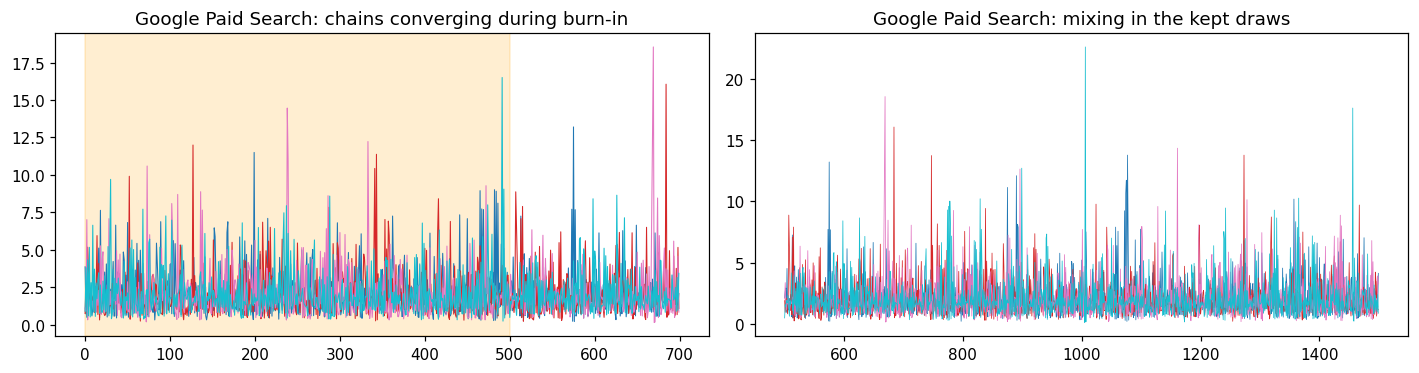

In [152]:
# zoom: burn-in behaviour of one parameter across chains, plus mixing after
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 3.5))
for c in range(n_c):
    ax1.plot(post['roi_m'][c, :N_BURNIN_VIS + 200, 0], lw=0.7, color=chain_colors[c])
    ax2.plot(np.arange(N_BURNIN_VIS, n_d), post['roi_m'][c, N_BURNIN_VIS:, 0],
             lw=0.5, color=chain_colors[c])
ax1.axvspan(0, N_BURNIN_VIS, color='orange', alpha=0.18)
ax1.set_title(f'{channels[0]}: chains converging during burn-in')
ax2.set_title(f'{channels[0]}: mixing in the kept draws')
plt.tight_layout(); plt.show()


### Discard the visualised burn-in before inference

Everything downstream (diagnostics, ROI, contributions, optimisation) must use only post-burn-in draws.

In [153]:
idata_full = mmm.inference_data.posterior.copy(deep=True)  # keep full history for reference
mmm.inference_data.posterior = mmm.inference_data.posterior.isel(
    draw=slice(N_BURNIN_VIS, None))
post = mmm.inference_data.posterior
print('Draws per chain after discarding burn-in:', post.sizes['draw'])
print('Total inference samples:', post.sizes['chain'] * post.sizes['draw'])


Draws per chain after discarding burn-in: 1000
Total inference samples: 4000


## 10. Convergence diagnostics — R-hat & ESS

Rule of thumb: **R-hat < 1.01** (≤1.05 acceptable) and effective sample size (ESS) comfortably in the hundreds for the parameters you report.

In [154]:
summ = az.summary(mmm.inference_data, var_names=['roi_m'], round_to=3)
summ.index = channels
display(summ[['mean', 'sd', 'hdi_3%', 'hdi_97%', 'ess_bulk', 'ess_tail', 'r_hat']])

model_diagnostics = visualizer.ModelDiagnostics(mmm)
model_diagnostics.plot_rhat_boxplot()


,mean,sd,hdi_3%,hdi_97%,ess_bulk,ess_tail,r_hat
Google Paid Search,2.118,1.700,0.262,5.006,8962.244,2876.258,1.003
Google Shopping,2.080,1.369,0.251,4.550,2001.854,2411.608,1.001
Google PMax,2.426,1.682,0.286,5.488,2229.804,3229.370,1.002
Meta Facebook,2.071,1.531,0.300,4.839,8650.868,3260.183,1.001


alt.LayerChart(...)

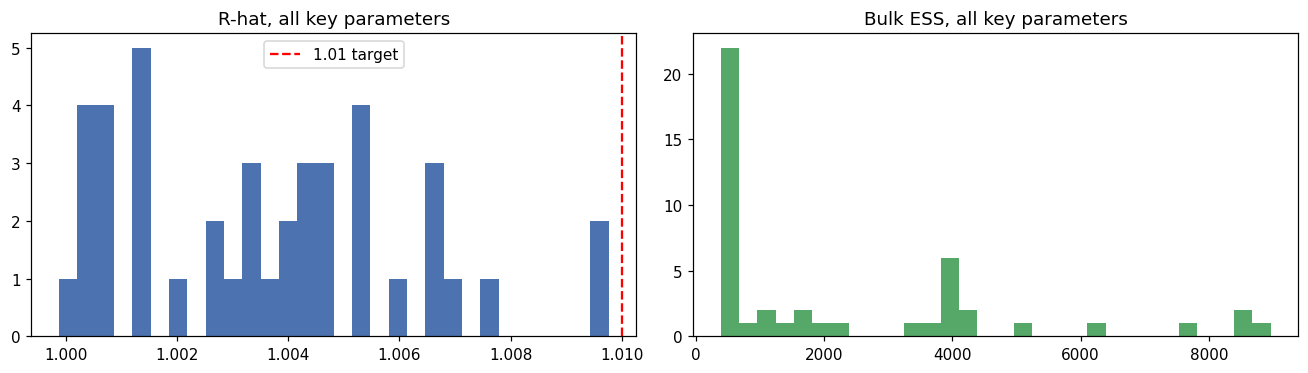

In [155]:
# ESS + R-hat overview across all major parameter blocks
blocks = [v for v in ['roi_m', 'ec_m', 'slope_m', 'alpha_m', 'gamma_c', 'knot_values'] if v in post]
rhat = az.rhat(mmm.inference_data, var_names=blocks)
ess  = az.ess(mmm.inference_data, var_names=blocks)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].hist(np.concatenate([rhat[v].values.ravel() for v in blocks]), bins=30, color='#4C72B0')
axes[0].axvline(1.01, color='red', ls='--', label='1.01 target'); axes[0].legend()
axes[0].set_title('R-hat, all key parameters')
axes[1].hist(np.concatenate([ess[v].values.ravel() for v in blocks]), bins=30, color='#55A868')
axes[1].set_title('Bulk ESS, all key parameters')
plt.tight_layout(); plt.show()


## 11. Prior vs. posterior

If the posterior departs clearly from the prior, the data is informative about that parameter; if it just reproduces the prior, the estimate is prior-driven — treat it with care (common for tiny channels).

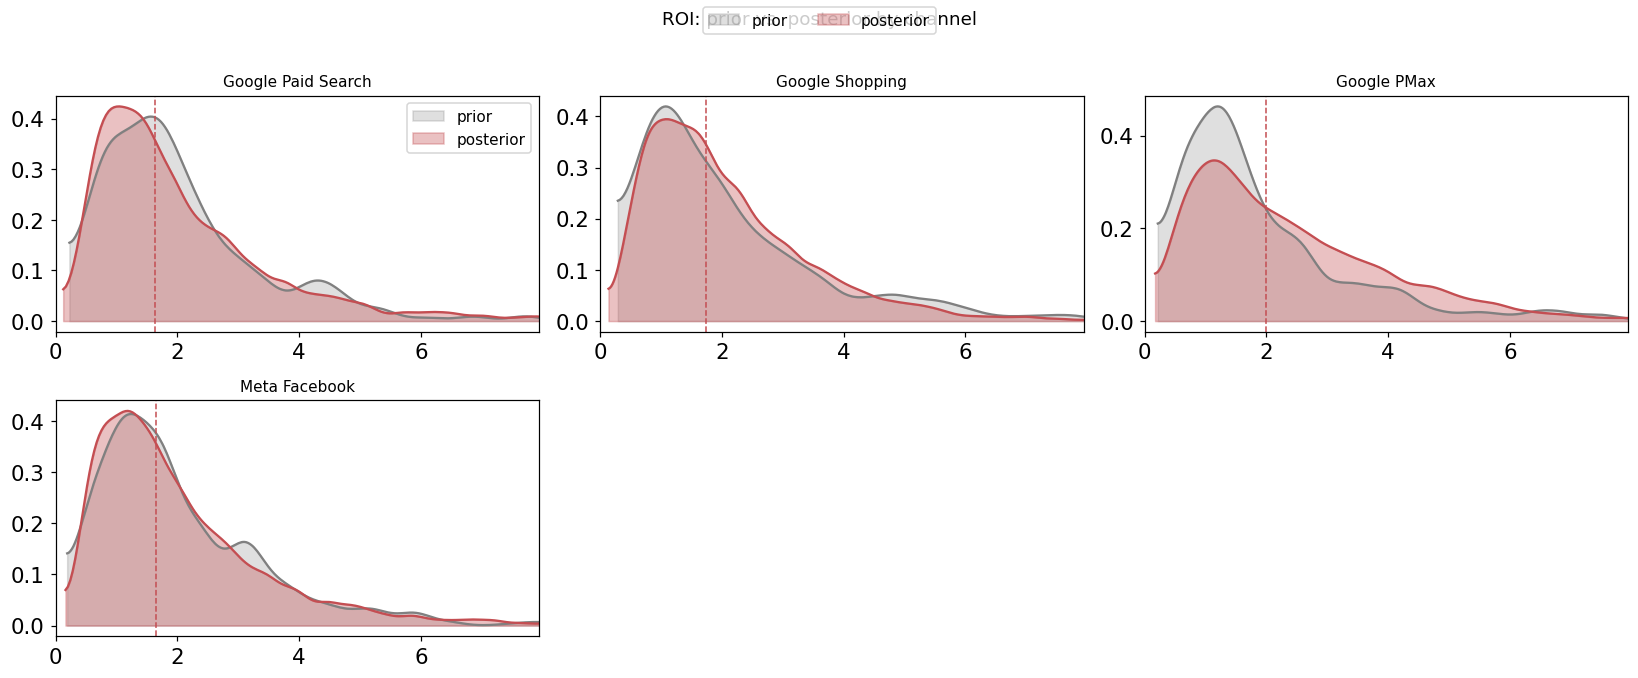

In [156]:
prior_roi = mmm.inference_data.prior['roi_m'].values.reshape(-1, len(channels))
post_roi  = post['roi_m'].values.reshape(-1, len(channels))

fig, axes = plt.subplots((n_ch + 2) // 3, 3, figsize=(15, 3 * ((n_ch + 2) // 3)), squeeze=False)
for k, ch in enumerate(channels):
    ax = axes[k // 3][k % 3]
    az.plot_dist(prior_roi[:, k], ax=ax, color='grey',
                 label='prior' if k == 0 else None, fill_kwargs={'alpha': 0.25})
    az.plot_dist(post_roi[:, k], ax=ax, color='#C44E52',
                 label='posterior' if k == 0 else None, fill_kwargs={'alpha': 0.35})
    ax.axvline(np.median(post_roi[:, k]), color='#C44E52', ls='--', lw=1)
    ax.set_title(ch, fontsize=10); ax.set_xlim(0, np.percentile(prior_roi, 99))
fig.legend(loc='upper center', ncol=2)
fig.suptitle('ROI: prior vs. posterior by channel', y=1.02)
for k in range(n_ch, axes.size):
    axes[k // 3][k % 3].axis('off')
plt.tight_layout(); plt.show()


In [157]:
# Meridian's built-in prior/posterior plot for other parameter blocks
model_diagnostics.plot_prior_and_posterior_distribution()


alt.FacetChart(...)

## 12. Model fit — expected vs. actual revenue

In [158]:
model_fit = visualizer.ModelFit(mmm)
model_fit.plot_model_fit()


alt.LayerChart(...)

In [159]:
model_fit.plot_model_fit(n_top_largest_geos=min(4, n_geos), show_geo_level=True)


alt.FacetChart(...)

In [160]:
mmm_analyzer = analyzer.Analyzer(mmm)
fit_metrics = mmm_analyzer.predictive_accuracy()   # xarray Dataset: R2, MAPE, wMAPE
fit_metrics.to_dataframe().unstack()


value          
geo_granularity       geo  national
metric                             
R_Squared        0.973564  0.984393
MAPE             0.182282  0.073088
wMAPE            0.137502  0.070758

## 13. Control variables

Posterior coefficients (`gamma_c`) for the organic/owned traffic controls. Positive = weeks with more of this traffic have higher baseline revenue, media held fixed. These absorb demand shifts so media doesn't take credit for them.

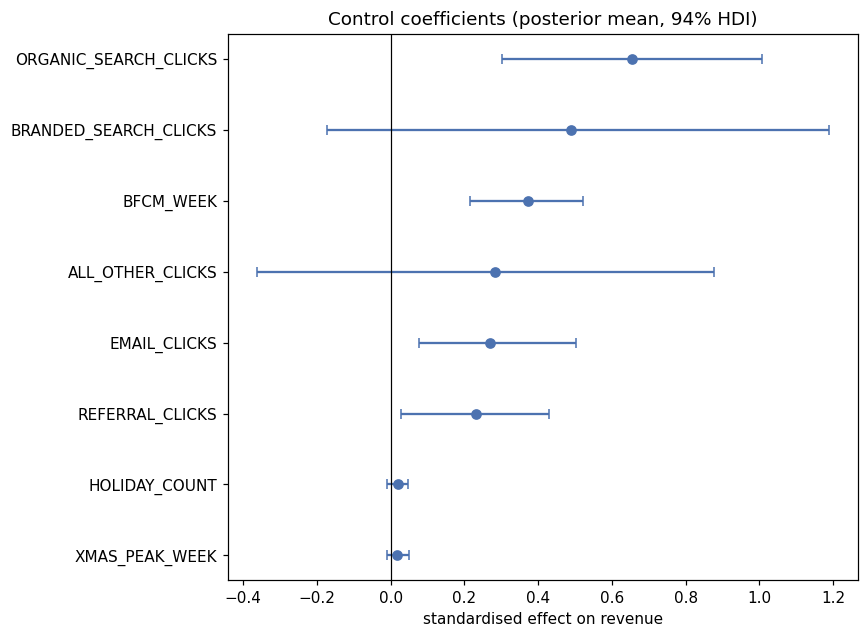

In [161]:
gamma = post['gamma_c']  # (chain, draw, control)
ctrl_names = list(post['control_variable'].values)
means = gamma.mean(dim=('chain', 'draw')).values
hdi = az.hdi(mmm.inference_data, var_names=['gamma_c'])['gamma_c'].values

order = np.argsort(means)
fig, ax = plt.subplots(figsize=(8, 0.55 * len(ctrl_names) + 1.5))
ax.errorbar(means[order], np.arange(len(ctrl_names)),
            xerr=np.abs(hdi[order].T - means[order]), fmt='o',
            color='#4C72B0', ecolor='#4C72B0', capsize=3)
ax.axvline(0, color='k', lw=0.8)
ax.set_yticks(np.arange(len(ctrl_names)), [ctrl_names[i] for i in order])
ax.set_title('Control coefficients (posterior mean, 94% HDI)')
ax.set_xlabel('standardised effect on revenue')
plt.tight_layout(); plt.show()


## 14. Results — ROI, contributions, response curves, adstock

In [162]:
media_summary = visualizer.MediaSummary(mmm)
media_summary.summary_table()


,channel,distribution,impressions,% impressions,spend,% spend,cpm,incremental outcome,% contribution,roi,effectiveness,mroi,cpik
0,Google Paid Search,prior,"622,189",0.1%,"$36,573",0.9%,$59,"$78,172 ($20,815, $174,486)","0.1% (0.0%, 0.1%)","2.1 (0.6, 4.8)","0.13 (0.03, 0.28)","0.7 (0.2, 1.7)","$0.6 ($0.2, $1.8)"
1,Google Paid Search,posterior,"622,189",0.1%,"$36,573",0.9%,$59,"$77,454 ($19,777, $187,537)","0.1% (0.0%, 0.2%)","2.1 (0.5, 5.1)","0.12 (0.03, 0.30)","0.7 (0.1, 1.7)","$0.6 ($0.2, $1.8)"
2,Google Shopping,prior,"423,376,448",92.3%,"$3,424,078",88.5%,$8,"$7,486,550 ($1,895,574, $18,943,942)","5.9% (1.5%, 14.9%)","2.2 (0.6, 5.5)","0.02 (0.00, 0.04)","1.1 (0.2, 2.9)","$0.6 ($0.2, $1.8)"
3,Google Shopping,posterior,"423,376,448",92.3%,"$3,424,078",88.5%,$8,"$7,122,007 ($1,872,440, $16,315,698)","6.9% (1.8%, 15.8%)","2.1 (0.5, 4.8)","0.02 (0.00, 0.04)","1.1 (0.2, 2.6)","$0.6 ($0.2, $1.8)"
4,Google PMax,prior,"29,564,898",6.4%,"$375,023",9.7%,$13,"$748,865 ($192,205, $2,007,843)","0.6% (0.2%, 1.6%)","2.0 (0.5, 5.4)","0.03 (0.01, 0.07)","0.9 (0.2, 2.3)","$0.7 ($0.2, $2.0)"
5,Google PMax,posterior,"29,564,898",6.4%,"$375,023",9.7%,$13,"$909,726 ($202,438, $2,114,018)","0.9% (0.2%, 2.0%)","2.4 (0.5, 5.6)","0.03 (0.01, 0.07)","1.0 (0.2, 2.2)","$0.5 ($0.2, $1.9)"
6,Meta Facebook,prior,"5,173,425",1.1%,"$35,389",0.9%,$7,"$75,977 ($19,151, $182,158)","0.1% (0.0%, 0.1%)","2.1 (0.5, 5.1)","0.01 (0.00, 0.04)","0.8 (0.2, 2.1)","$0.6 ($0.2, $1.8)"
7,Meta Facebook,posterior,"5,173,425",1.1%,"$35,389",0.9%,$7,"$73,310 ($18,679, $177,337)","0.1% (0.0%, 0.2%)","2.1 (0.5, 5.0)","0.01 (0.00, 0.03)","0.8 (0.2, 2.0)","$0.6 ($0.2, $1.9)"
8,All Channels,prior,"458,736,960",100.0%,"$3,871,064",100.0%,$8,"$8,389,560 ($2,736,486, $19,646,738)","6.6% (2.2%, 15.5%)","2.2 (0.7, 5.1)","nan (nan, nan)","nan (nan, nan)","$0.6 ($0.2, $1.4)"
9,All Channels,posterior,"458,736,960",100.0%,"$3,871,064",100.0%,$8,"$8,182,508 ($2,791,118, $17,365,522)","7.9% (2.7%, 16.8%)","2.1 (0.7, 4.5)","nan (nan, nan)","nan (nan, nan)","$0.6 ($0.2, $1.4)"


In [163]:
media_summary.plot_roi_bar_chart()


alt.LayerChart(...)

In [164]:
media_summary.plot_contribution_waterfall_chart()


alt.LayerChart(...)

In [165]:
media_summary.plot_channel_contribution_area_chart()


alt.Chart(...)

In [166]:
media_effects = visualizer.MediaEffects(mmm)
media_effects.plot_response_curves()


alt.FacetChart(...)

In [167]:
media_effects.plot_adstock_decay()


alt.FacetChart(...)

In [168]:
media_effects.plot_hill_curves()


{'media': alt.FacetChart(...)}

In [169]:
# ROI point estimates + credible intervals as a tidy table
roi_tbl = pd.DataFrame({
    'channel': channels,
    'roi_median': np.median(post['roi_m'].values.reshape(-1, len(channels)), axis=0),
    'roi_mean': post['roi_m'].values.reshape(-1, len(channels)).mean(axis=0),
    'roi_lo_5%': np.percentile(post['roi_m'].values.reshape(-1, len(channels)), 5, axis=0),
    'roi_hi_95%': np.percentile(post['roi_m'].values.reshape(-1, len(channels)), 95, axis=0),
    'total_spend': [model_df[c[0]].sum() for c in ACTIVE_CHANNELS],
}).sort_values('roi_median', ascending=False).round(2)
roi_tbl


,channel,roi_median,roi_mean,roi_lo_5%,roi_hi_95%,total_spend
2,Google PMax,2.00,2.43,0.54,5.64,375023.30
1,Google Shopping,1.74,2.08,0.55,4.76,3424078.07
3,Meta Facebook,1.66,2.07,0.53,5.01,35389.42
0,Google Paid Search,1.64,2.12,0.54,5.13,36573.08


## 15. Budget optimization

Given the fitted response curves, reallocate the historical budget to maximise incremental revenue (default: ±30% spend bounds per channel).

In [183]:
optimization_results.output_optimization_summary

<bound method OptimizationResults.output_optimization_summary of OptimizationResults(analyzer=<meridian.analysis.analyzer.Analyzer object at 0x15ba53a10>, spend_ratio=<xarray.DataArray 'non_optimized' (channel: 4)> Size: 32B
array([1.01167333, 0.99997715, 0.99993767, 0.98899631])
Coordinates:
  * channel  (channel) <U18 288B 'Google Paid Search' ... 'Meta Facebook', spend_bounds=(array([0.7]), array([1.3])), _nonoptimized_data=<xarray.Dataset> Size: 832B
Dimensions:              (channel: 4, metric: 4)
Coordinates:
  * channel              (channel) object 32B 'Google Paid Search' ... 'Meta ...
  * metric               (metric) <U6 96B 'mean' 'median' 'ci_lo' 'ci_hi'
Data variables:
    spend                (channel) float64 32B 3.7e+04 3.424e+06 ... 3.5e+04
    pct_of_spend         (channel) float64 32B 0.009558 0.8845 0.09687 0.009042
    incremental_outcome  (channel, metric) float64 128B 7.774e+04 ... 1.764e+05
    effectiveness        (channel, metric) float64 128B 0.1235 ... 0.03

In [170]:
budget_optimizer = optimizer.BudgetOptimizer(mmm)
optimization_results = budget_optimizer.optimize()
optimization_results.plot_incremental_outcome_delta()


alt.LayerChart(...)

In [171]:
optimization_results.plot_budget_allocation()


alt.Chart(...)

In [172]:
optimization_results.plot_response_curves()


alt.FacetChart(...)

In [173]:
# exportable optimization report
optimization_results.output_optimization_summary(
    filename='budget_optimization_report.html', filepath='.')
print('Saved budget_optimization_report.html')


Saved budget_optimization_report.html


## 16. Two-page HTML model summary & saving the model

In [174]:
mmm_summarizer = summarizer.Summarizer(mmm)
start, end = model_df['time'].min(), model_df['time'].max()
mmm_summarizer.output_model_results_summary(
    filename='mmm_results_summary.html', filepath='.',
    start_date=start, end_date=end)
print('Saved mmm_results_summary.html')


Saved mmm_results_summary.html


In [175]:
import shutil
save_dir = 'saved_model'
if os.path.exists(save_dir):
    shutil.rmtree(save_dir)          # save_mmm creates the directory itself
model.save_mmm(mmm, os.path.join(save_dir, 'meridian_mmm.pkl'))
print('Model saved -> saved_model/meridian_mmm.pkl (reload with model.load_mmm)')


Model saved -> saved_model/meridian_mmm.pkl (reload with model.load_mmm)


## 17. Caveats & next steps

- **Currency**: if geos use different currencies, convert to one before modelling — ROI comparisons across geos are otherwise meaningless.
- **Discount fields**: `*_GROSS_DISCOUNT` is only observed for completed purchases — using discount *rate* as a control leaks the outcome (per the data dictionary). We excluded it.
- **Branded search / direct clicks as controls**: these partially *mediate* paid media (ads drive brand searches), so including them can under-credit upper-funnel channels. Test sensitivity by re-running with `CONTROL_COLS` reduced to `ORGANIC_SEARCH_CLICKS` + `EMAIL_CLICKS`.
- **Calibration**: replace the shared ROI prior with channel-specific priors from lift tests / geo experiments (`roi_m` with per-channel `mu`, `sigma` arrays) — this is Meridian's main calibration mechanism.
- **Reach & frequency**: if you can export R&F for Meta/TikTok, use Meridian's `rf_*` inputs for better video/social measurement.
- **Convergence**: if any R-hat > 1.05, increase `N_ADAPT`/`N_KEEP`, or simplify (fewer knots, merge tiny channels).
- **New-customer MMM**: swap the KPI to `FIRST_PURCHASES` (with `kpi_type='non_revenue'` and `revenue_per_kpi`) to model acquisitions instead of revenue.
